# Laboratorium MLOps 01: DVC od podstaw do odtwarzalnych eksperymentów

**Zbiór:** [Wine Quality (UCI)](https://archive.ics.uci.edu/dataset/186/wine+quality) · **Język:** Python ·


## Agenda

Umiejętności. Student potrafi:
1. odróżnić wersjonowanie kodu (Git) od wersjonowania danych (DVC);
2. odtworzyć wersję danych, na której trenowano model;
3. opisać pipeline z zależnościami, parametrami i metrykami;
4. przeprowadzić i porównać eksperymenty ML;
5. udostępnić artefakty przez lokalny *DVC remote*.

**Uwaga organizacyjna:** notebook tworzy własny katalog `dvc_wine_lab` obok notebooka. Uruchamiaj komórki **w kolejności**. Nie uruchamiaj ponownie komórek inicjalizujących, jeśli chcesz zachować historię swoich rozwiązań. Polecenia wykonywane są w katalogu projektu przez funkcję `run()`; nie trzeba używać `!cd`.

## 0. Instalacja i wymagania

Wymagane: Python ≥ 3.10, Git w PATH, dostęp do internetu **tylko do pierwszego pobrania danych i instalacji pakietów**. Rekomendowane: osobne środowisko wirtualne i uruchomienie lokalnego JupyterLab.

Przykład terminala:
```bash
python -m venv .venv
# macOS/Linux: source .venv/bin/activate
# Windows: .venv\Scripts\activate
pip install jupyterlab dvc pandas scikit-learn pyyaml matplotlib
jupyter-lab
```

Poniższa komórka instaluje pakiety w aktualnym kernelu (gdy brakuje ich w środowisku).

In [1]:
print("Hello World")

Hello World


In [2]:
import importlib.util, subprocess, sys
packages = {"dvc": "dvc", "pandas": "pandas", "sklearn": "scikit-learn", "yaml": "pyyaml", "matplotlib": "matplotlib"}
missing = [pkg for module, pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
print("Pakiety Python: OK")
subprocess.run(["git", "--version"], check=True)
subprocess.run([sys.executable, "-m", "dvc", "--version"], check=True)

Pakiety Python: OK
git version 2.47.3
3.67.1


CompletedProcess(args=['/usr/local/bin/python3.12', '-m', 'dvc', '--version'], returncode=0)

## 1. Projekt, Git i DVC

**Git** zapisuje historię kodu i małych plików metadanych. **DVC** zapisuje metadane wersji danych, przechowuje zawartość w cache i może synchronizować dane z magazynem zewnętrznym. Plik `.dvc` **nie zawiera** całego zbioru danych.

Każda komórka wykorzystuje funkcję `run`, która zatrzyma wykonywanie w razie błędu. Konfiguracja nazwy/email w Git jest **lokalna dla przykładowego repozytorium**.

In [3]:
from pathlib import Path
import os, subprocess, sys, json, textwrap
ROOT = (Path.cwd() / "dvc_wine_lab").resolve()
ROOT.mkdir(exist_ok=True)

def run(*args, check=True):
    cmd = [str(x) for x in args]
    print("$", " ".join(cmd))
    return subprocess.run(cmd, cwd=ROOT, check=check, text=True)

def dvc(*args):
    return run(sys.executable, "-m", "dvc", *args)

def write(relpath, content):
    path = ROOT / relpath
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(textwrap.dedent(content).lstrip(), encoding="utf-8")
    return path

if not (ROOT / ".git").exists():
    run("git", "init")
run("git", "config", "user.name", "Student DVC")
run("git", "config", "user.email", "student@example.invalid")
if not (ROOT / ".dvc").exists():
    dvc("init")
print("Projekt:", ROOT)

$ git init
Initialized empty Git repository in /app/dvc_wine_lab/.git/
$ git config user.name Student DVC
$ git config user.email student@example.invalid
$ /usr/local/bin/python3.12 -m dvc init


hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint:
hint: 	git config --global init.defaultBranch <name>
hint:
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint:
hint: 	git branch -m <name>


Initialized DVC repository.

You can now commit the changes to git.

+---------------------------------------------------------------------+
|                                                                     |
|        DVC has enabled anonymous aggregate usage analytics.         |
|     Read the analytics documentation (and how to opt-out) here:     |
|             <https://dvc.org/doc/user-guide/analytics>              |
|                                                                     |
+---------------------------------------------------------------------+

What's next?
------------
- Check out the documentation: <https://dvc.org/doc>
- Get help and share ideas: <https://dvc.org/chat>
- Star us on GitHub: <https://github.com/treeverse/dvc>
Projekt: /app/dvc_wine_lab


## 2. Publiczny zbiór danych: Wine Quality

Używamy *winequality-red.csv*, klasycznego zbioru regresyjnego. Kolumny obejmują m.in. zawartość alkoholu, kwasowość i docelową ocenę `quality`. Źródło: Cortez i in. (2009), UCI, DOI: [10.24432/C56S3T](https://doi.org/10.24432/C56S3T), CC BY 4.0.

Plik zostanie pobrany tylko raz. W przypadku braku internetu instruktor może udostępnić plik CSV w `dvc_wine_lab/data/raw/`.

In [4]:
import urllib.request
import pandas as pd
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
raw_path = ROOT / "data/raw/winequality-red.csv"
raw_path.parent.mkdir(parents=True, exist_ok=True)
if not raw_path.exists():
    try:
        urllib.request.urlretrieve(DATA_URL, raw_path)
    except Exception as exc:
        raise RuntimeError("Pobranie nieudane. Wgraj winequality-red.csv ręcznie do data/raw/") from exc
frame = pd.read_csv(raw_path, sep=";")
assert "quality" in frame and len(frame) > 1000
print("Rozmiar:", frame.shape)
display(frame.head())
display(frame["quality"].value_counts().sort_index())

Rozmiar: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

### Pierwszy śledzony plik

Polecenie `dvc add` tworzy plik `*.dvc` i rejestruje zawartość danych w cache DVC. Do Gita dodajemy plik metadanych, a nie sam CSV.

In [5]:
if not (ROOT / "data/raw/winequality-red.csv.dvc").exists():
    dvc("add", "data/raw/winequality-red.csv")
run("git", "add", ".dvc", "data/raw/winequality-red.csv.dvc", "data/raw/.gitignore")
run("git", "status", "--short")
if not (ROOT / ".git/refs/heads/main").exists() and not (ROOT / ".git/refs/heads/master").exists():
    run("git", "commit", "-m", "Initialize DVC and track wine dataset")
print((ROOT / "data/raw/winequality-red.csv.dvc").read_text())

$ /usr/local/bin/python3.12 -m dvc add data/raw/winequality-red.csv


⠋ Checking graph



To track the changes with git, run:

	git add data/raw/winequality-red.csv.dvc data/raw/.gitignore

To enable auto staging, run:

	dvc config core.autostage true
$ git add .dvc data/raw/winequality-red.csv.dvc data/raw/.gitignore
$ git status --short
A  .dvc/.gitignore
A  .dvc/config
A  .dvcignore
A  data/raw/.gitignore
A  data/raw/winequality-red.csv.dvc
$ git commit -m Initialize DVC and track wine dataset
[master (root-commit) f341eb3] Initialize DVC and track wine dataset
 5 files changed, 12 insertions(+)
 create mode 100644 .dvc/.gitignore
 create mode 100644 .dvc/config
 create mode 100644 .dvcignore
 create mode 100644 data/raw/.gitignore
 create mode 100644 data/raw/winequality-red.csv.dvc
outs:
- md5: 2daeecee174368f8a33b82c8cccae3a5
  size: 84199
  hash: md5
  path: winequality-red.csv



**Pytania:** Dlaczego zwykły `git add data/raw/winequality-red.csv` nie jest tu właściwym rozwiązaniem? Co znaczy hash w pliku `.dvc`? Czy usunięcie CSV z katalogu roboczego oznacza utratę danych?

## 3. Reprodukowalny pipeline: prepare → train

DVC pozwala opisać: **komendę (`cmd`)**, **zależności (`deps`)**, **wyniki (`outs`)**, **parametry (`params`)** i **metryki (`metrics`)**. Dla uproszczenia zastosujemy podział train/test, model `RandomForestRegressor` i metryki MAE, RMSE, R².

Ważne: train/test split ma stałe ziarno, a ten sam zestaw testowy wykorzystujemy we wszystkich eksperymentach.

In [6]:
write("params.yaml", """
prepare:
  test_size: 0.2
  random_state: 42
train:
  n_estimators: 50
  max_depth: 8
  random_state: 42
""")
write("src/prepare.py", """
from pathlib import Path
import pandas as pd
import yaml
from sklearn.model_selection import train_test_split

p = yaml.safe_load(Path('params.yaml').read_text())['prepare']
df = pd.read_csv('data/raw/winequality-red.csv', sep=';')
train, test = train_test_split(df, test_size=p['test_size'], random_state=p['random_state'])
Path('data/processed').mkdir(parents=True, exist_ok=True)
train.to_csv('data/processed/train.csv', index=False)
test.to_csv('data/processed/test.csv', index=False)
print('train/test:', len(train), len(test))
""")
write("src/train.py", """
from pathlib import Path
import json
import joblib
import pandas as pd
import yaml
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

p = yaml.safe_load(Path('params.yaml').read_text())['train']
train = pd.read_csv('data/processed/train.csv')
test = pd.read_csv('data/processed/test.csv')
X_train, y_train = train.drop(columns=['quality']), train['quality']
X_test, y_test = test.drop(columns=['quality']), test['quality']
model = RandomForestRegressor(**p, n_jobs=1)
model.fit(X_train, y_train)
pred = model.predict(X_test)
metrics = {
    'mae': float(mean_absolute_error(y_test, pred)),
    'rmse': float(mean_squared_error(y_test, pred)**0.5),
    'r2': float(r2_score(y_test, pred)),
}
Path('models').mkdir(exist_ok=True)
Path('reports').mkdir(exist_ok=True)
joblib.dump(model, 'models/model.joblib')
Path('reports/metrics.json').write_text(json.dumps(metrics, indent=2))
print(metrics)
""")
write("dvc.yaml", """
stages:
  prepare:
    cmd: python src/prepare.py
    deps:
      - data/raw/winequality-red.csv
      - src/prepare.py
    params:
      - prepare.test_size
      - prepare.random_state
    outs:
      - data/processed/train.csv
      - data/processed/test.csv
  train:
    cmd: python src/train.py
    deps:
      - data/processed/train.csv
      - data/processed/test.csv
      - src/train.py
    params:
      - train.n_estimators
      - train.max_depth
      - train.random_state
    outs:
      - models/model.joblib
    metrics:
      - reports/metrics.json
""")
print("Wygenerowano: params.yaml, dvc.yaml, src/prepare.py, src/train.py")

Wygenerowano: params.yaml, dvc.yaml, src/prepare.py, src/train.py


**Uwaga:** polecenie `python` w `dvc.yaml` musi wskazywać środowisko, w którym zainstalowano `scikit-learn`, `pandas`, `PyYAML` i `joblib`. Najprościej uruchomić Jupyter z tego samego aktywnego środowiska wirtualnego. Dla systemów, na których `python` wskazuje inny interpreter, zastąp tę komendę ścieżką do właściwego Pythona.

In [16]:
dvc("repro")
dvc("metrics", "show")
dvc("status")
run("git", "add", "src", "params.yaml", "dvc.yaml", "dvc.lock")
run("git", "commit", "-m", "Add reproducible ML pipeline")

$ /usr/local/bin/python3.12 -m dvc repro
'data/raw/winequality-red.csv.dvc' didn't change, skipping
Stage 'prepare' didn't change, skipping
Stage 'train' didn't change, skipping
Data and pipelines are up to date.
$ /usr/local/bin/python3.12 -m dvc metrics show
Path                  mae      r2       rmse
reports/metrics.json  0.45864  0.49486  0.57455
$ /usr/local/bin/python3.12 -m dvc status
Data and pipelines are up to date.
$ git add src params.yaml dvc.yaml dvc.lock
$ git commit -m Add reproducible ML pipeline
[master a49f920] Add reproducible ML pipeline
 5 files changed, 126 insertions(+)
 create mode 100644 dvc.lock
 create mode 100644 dvc.yaml
 create mode 100644 params.yaml
 create mode 100644 src/prepare.py
 create mode 100644 src/train.py


CompletedProcess(args=['git', 'commit', '-m', 'Add reproducible ML pipeline'], returncode=0)

## 4. Wizualizacja danych i wyników

Jupyter może służyć do eksploracji. DVC uruchamia **skrypty pipeline’u**, dlatego wyniki można odtworzyć również na komputerze bez notebooka.

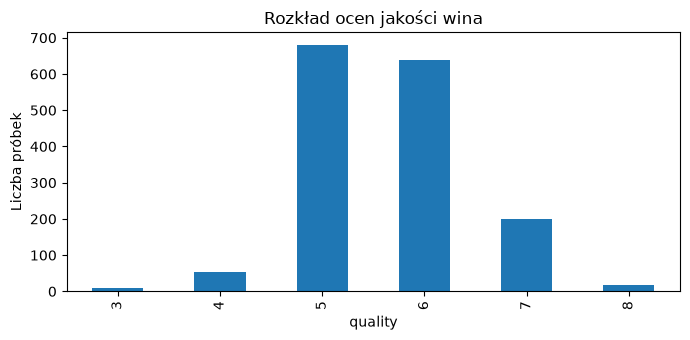

{'mae': 0.4586366286503467, 'rmse': 0.5745522557763956, 'r2': 0.4948625327805698}


In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.5))
frame["quality"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set(title="Rozkład ocen jakości wina", xlabel="quality", ylabel="Liczba próbek")
plt.tight_layout()
plt.show()
print(json.loads((ROOT / "reports/metrics.json").read_text()))

## 5. Eksperymenty DVC

Eksperymenty są zapisami zmian konfiguracji i rezultatów, możliwymi do porównania. Zmienimy liczbę drzew bez ręcznej edycji `params.yaml`.

In [8]:
dvc("exp", "run", "--set-param", "train.n_estimators=20")
dvc("exp", "run", "--set-param", "train.n_estimators=100")
dvc("exp", "show")

$ /usr/local/bin/python3.12 -m dvc exp run --set-param train.n_estimators=20
Reproducing experiment 'zesty-kibe'
'data/raw/winequality-red.csv.dvc' didn't change, skipping
Stage 'prepare' didn't change, skipping
Running stage 'train':
> python src/train.py
{'mae': 0.46734110488571956, 'rmse': 0.5900246903294627, 'r2': 0.46728995585238964}
Updating lock file 'dvc.lock'

Ran experiment(s): zesty-kibe
Experiment results have been applied to your workspace.
$ /usr/local/bin/python3.12 -m dvc exp run --set-param train.n_estimators=100
Reproducing experiment 'mural-corm'
'data/raw/winequality-red.csv.dvc' didn't change, skipping
Stage 'prepare' didn't change, skipping
Running stage 'train':
> python src/train.py
{'mae': 0.4586366286503467, 'rmse': 0.5745522557763956, 'r2': 0.4948625327805698}
Updating lock file 'dvc.lock'

Ran experiment(s): mural-corm
Experiment results have been applied to your workspace.
$ /usr/local/bin/python3.12 -m dvc exp show
 ────────────────────────────────────────

CompletedProcess(args=['/usr/local/bin/python3.12', '-m', 'dvc', 'exp', 'show'], returncode=0)

W tabeli eksperymentów porównaj MAE/RMSE/R². **Niższe MAE/RMSE jest lepsze; wyższe R² jest lepsze.** Zwróć uwagę, czy różnice są duże i czy dodatkowe drzewa uzasadniają koszt treningu. Aby przywrócić bazowy pipeline po eksperymentach, wykonaj poniższe polecenie.

In [11]:
dvc("repro")
dvc("metrics", "show")

$ /usr/local/bin/python3.12 -m dvc repro
'data/raw/winequality-red.csv.dvc' didn't change, skipping
Stage 'prepare' didn't change, skipping
Stage 'train' didn't change, skipping
Data and pipelines are up to date.
$ /usr/local/bin/python3.12 -m dvc metrics show
Path                  mae      r2       rmse
reports/metrics.json  0.45864  0.49486  0.57455


CompletedProcess(args=['/usr/local/bin/python3.12', '-m', 'dvc', 'metrics', 'show'], returncode=0)

## 6. Lokalny DVC remote: push/pull

*Remote* DVC może być zwykłym folderem na dysku! Aby zasymulować współdzielony magazyn, utworzymy go **poza** repozytorium. Dzięki temu przećwiczysz pełny cykl bez S3, GCS czy konta w chmurze.

In [12]:
REMOTE = ROOT.parent / "dvc_wine_remote"
REMOTE.mkdir(exist_ok=True)
run("git", "status", "--short")
# -f umożliwia powtórne uruchomienie komórki w trakcie laboratorium.
dvc("remote", "add", "-d", "-f", "localstore", str(REMOTE))
dvc("push")
print("Lokalny magazyn:", REMOTE)
print("Pliki w magazynie:", sum(1 for p in REMOTE.rglob('*') if p.is_file()))

$ git status --short
?? data/processed/
?? data/raw/.ipynb_checkpoints/
?? dvc.lock
?? dvc.yaml
?? models/
?? params.yaml
?? reports/
?? src/
$ /usr/local/bin/python3.12 -m dvc remote add -d -f localstore /app/dvc_wine_remote
Setting 'localstore' as a default remote.
$ /usr/local/bin/python3.12 -m dvc push
5 files pushed
Lokalny magazyn: /app/dvc_wine_remote
Pliki w magazynie: 5


### Demonstracja odtwarzania danych

`dvc pull` pobiera dane z remote, a `dvc checkout` odtwarza właściwe wersje plików z lokalnego cache. W tym ćwiczeniu usuwamy tylko **jeden surowy CSV** z katalogu roboczego. Nie kasuj `.dvc` ani katalogu remote.

In [13]:
raw_path.unlink(missing_ok=True)
print("Plik istnieje po usunięciu?", raw_path.exists())
dvc("pull")
print("Plik odtworzony?", raw_path.exists())
assert raw_path.exists()
run("git", "add", ".dvc/config")
run("git", "commit", "-m", "Configure local DVC remote", check=False)

Plik istnieje po usunięciu? False
$ /usr/local/bin/python3.12 -m dvc pull
A       data/raw/winequality-red.csv
1 file added
Plik odtworzony? True
$ git add .dvc/config
$ git commit -m Configure local DVC remote
[master 00d273d] Configure local DVC remote
 1 file changed, 4 insertions(+)


CompletedProcess(args=['git', 'commit', '-m', 'Configure local DVC remote'], returncode=0)